In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph

    nodes, edges  = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})
    # LR = left to right

    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it

        dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name = uid + n._op, label = n._op)
            #and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot 

In [58]:
class Value:

    def __init__(self, data, _children=(), _op = '', label = ''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None 
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data = {self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)

        out = Value(self.data + other.data , (self, other), '+')
      
        def _backward():
          self.grad += 1.0 * out.grad
          other.grad += 1.0 * out.grad
        out._backward = _backward

        return out

    def __neg__(self):
       return self * -1

    def __sub__(self, other):
       return self + -(other)

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)

        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward

        return out

    def __rmul__(self, other):
       return self * other

    def __radd__(self, other):
       return self + other

    def __pow__(self, other):
       assert isinstance(other, (int, float)) #supporting int and float powers for now

       out = Value(self.data ** other, (self,), f'**{other}')

       def _backward():
          self.grad += other * (self.data**(other-1)) * out.grad

       out._backward = _backward 
       return out


    def __truediv__(self, other):
       return self * other**-1

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/ (math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad += (1- t**2) * out.grad
        out._backward = _backward

        return out 

    def exp(self):
       x = self.data
       out = Value(math.exp(x) , (self, ), 'exp')

       def _backward():
          self.grad += out.data * out.grad
       out._backward = _backward

       return out 

    def backward(self):
     topo = []
     visited = set()
     def build_topo(v):
        if v not in visited:
           visited.add(v)
           for child in v._prev:
             build_topo(child)
           topo.append(v)
     build_topo(self)

     self.grad = 1.0
     for node in reversed(topo):
        node._backward()    


In [4]:
a = Value(2.00)
b = 3 

c = a + b

# dc/dc = 1, dc/da = 1, dc/db = 1 dL/da = 1 * L.grad

e = a * b 

#de/de = 1, de/da = b, de/db = a, * L.grad

f = a**b 

#df/df = 1 , df/da = b*a**(b-1)

In [5]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

b = Value(6.8813735870195432, label='b')

x1w1 = x1*w1 ; x1w1.label = 'x1w1'
x2w2 = x2*w2 ; x2w2.label = 'x2w2'

x1w1x2w2 = x1w1 + x2w2 ; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b ; n.label  = 'n'
o = n.tanh(); o.label = 'o'

In [6]:
o.backward()

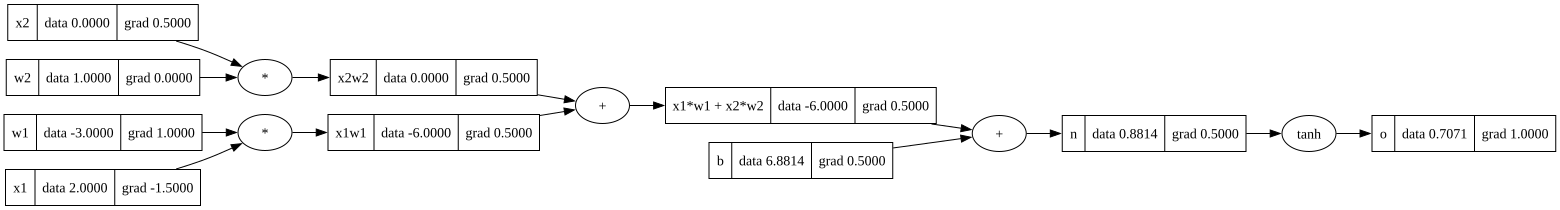

In [7]:
draw_dot(o)

In [11]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

b = Value(6.8813735870195432, label='b')

x1w1 = x1*w1 ; x1w1.label = 'x1w1'
x2w2 = x2*w2 ; x2w2.label = 'x2w2'

x1w1x2w2 = x1w1 + x2w2 ; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b ; n.label  = 'n'

#-------
o = ((2*n).exp() - 1) / (((2*n).exp() + 1))
#-------
o.label = 'o'
o.backward()

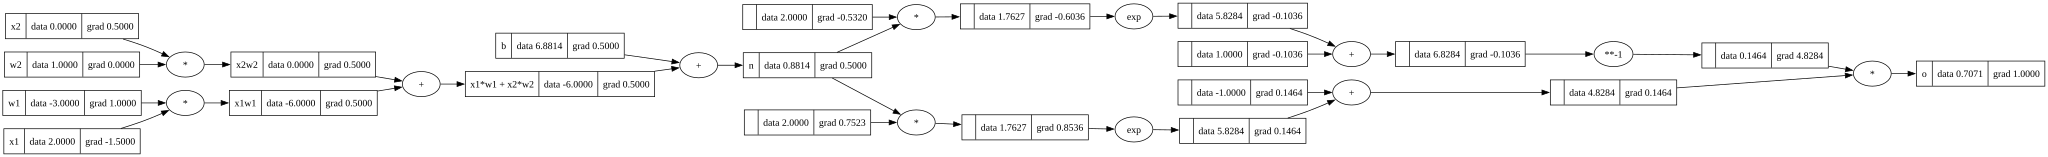

In [12]:
draw_dot(o)

In [90]:
class Neuron:

    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):

        act = sum((wi*xi for wi, xi in zip(self.w,x)), self.b)
        out = act.tanh()

        return out

    def parameters(self):
        return self.w + [self.b]
          

class Layer:

    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):

        # outs = []

        # for neuron in self.neurons:
        #     output = neuron(x)
        #     outs.append(output)

        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in  neuron.parameters()]

        # params = []
        # for neuron in self.neurons:
        #     ps = neuron.parameters()
        #     params.extend(ps)
        # return params

class MLP:

    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]
    


In [91]:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4,4,1])
n(x)

Value(data = 0.928204182479654)

In [ ]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]

ys = [1.0, -1.0, -1.0, 1.0]

[Value(data = 0.010668837241378553),
 Value(data = -0.4236155412555833),
 Value(data = -0.38773577994023317),
 Value(data = -0.1636002160308641)]

In [134]:
for k in range(20):

    # forward
    ypred = [n(x) for x in xs]
    loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))

    # backward
    for p in n.parameters():
        p.grad = 0.0

    loss.backward()

    #update
    for p in n.parameters():
        p.data += -0.05 * p.grad

    print(k, loss.data)

0 3.52661381110615e-21
1 3.52661381110615e-21
2 3.52661381110615e-21
3 3.52661381110615e-21
4 3.52661381110615e-21
5 3.52661381110615e-21
6 3.52661381110615e-21
7 3.52661381110615e-21
8 3.52661381110615e-21
9 3.52661381110615e-21
10 3.52661381110615e-21
11 3.52661381110615e-21
12 3.52661381110615e-21
13 3.52661381110615e-21
14 3.52661381110615e-21
15 3.52661381110615e-21
16 3.52661381110615e-21
17 3.52661381110615e-21
18 3.52661381110615e-21
19 3.52661381110615e-21
